In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from astropy.io import ascii as asc
from astropy.stats import sigma_clip

In [2]:
def load_lightcurve(path, cols=None, fmt=None):
    """
    Read a table and return (t, wl, f, err) as float arrays.

    cols : dict mapping standard names to this table's column names, e.g.
           {"t": "mjd", "wl": "lambda", "f": "flux", "err": "flux_err"}
    fmt  : astropy format string ("ipac", "csv", ...). None = auto-detect.
    """
    cols = cols or {"t": "mjd", "wl": "lambda", "f": "flux", "err": "flux_err"}
    tbl = asc.read(path, format=fmt) if fmt else asc.read(path)

    missing = [c for c in cols.values() if c not in tbl.colnames]
    if missing:
        raise KeyError(f"Columns {missing} not found. Available: {tbl.colnames}")

    return tuple(np.array(tbl[cols[k]], dtype=float) for k in ("t", "wl", "f", "err"))

#reading in the tables for the light curves

### Load_lightcurve(path, cols, fmt)
- #### **Job**: 
    - read one table and return four plain NumPy float arrays
- #### cols **dict**: 
    - maps the standard names ("t" modified julian dates, "wl" wavelength, "f" flux, "err" flux error) to the tables actual column names (mjd, lambda, flux, flux_err)
- #### asc.read(path) 
    - auto-detects the file format. if parsing goes wrong, pass fmt = "ipac" 
- #### the missing **check** 
    - raises a KeyError that lists the available columns, so a wrong column name is easy to fix.
- #### np.array(..., dtype=float) 
    - converts astropy comuns into simple float arrays. Masked entries become NaN
- #### **Returns the tuple**

In [3]:
def clean(t, wl, f, err, wl_range=(0.7, 5.0), err_pct=90, err_max=None,
          clip_sigma=3, n_bins=24, min_per_bin=4, verbose=True):
    """
    Apply quality cuts and per-wavelength-bin sigma clipping.
    All four arrays are masked together so they stay aligned.

    err_pct : drop errors above this percentile (None to skip)
    err_max : fixed error ceiling (overrides err_pct if given)
    clip_sigma : None to skip sigma clipping
    """
    n0 = len(f)
    good = np.isfinite(t) & np.isfinite(wl) & np.isfinite(f) & np.isfinite(err) & (err > 0)
    if wl_range is not None:
        good &= (wl > wl_range[0]) & (wl < wl_range[1])
    if err_max is not None:
        good &= err < err_max
    elif err_pct is not None:
        good &= err < np.nanpercentile(err[good], err_pct)
    t, wl, f, err = t[good], wl[good], f[good], err[good]
    n1 = len(f)

    if clip_sigma is not None and n1 > 0:
        edges = np.linspace(wl.min(), wl.max(), n_bins + 1)
        idx = np.digitize(wl, edges)
        keep = np.ones(n1, dtype=bool)
        for i in np.unique(idx):
            m = np.where(idx == i)[0]
            if len(m) >= min_per_bin:
                keep[m] = ~sigma_clip(f[m], sigma=clip_sigma, maxiters=5).mask
        t, wl, f, err = t[keep], wl[keep], f[keep], err[keep]

    if verbose:
        print(f"{n0} -> {n1} after quality cuts -> {len(f)} after clipping")
    return t, wl, f, err


## clean (t, wl, f, err, ...)

### Quality cuts

- all conditions are boolean arrays combine with **&**, so a point must pass every test. 
- #### np.isfinite
    - removes NaN/inf. and **err > 0** removes unphysical errors
- #### wl_range=(0.7,5.0)
    - keeps only the instrument's wl range
    - can set it =None to skip it if needed
- #### Error cut:
    - **err_pct = 90** drops the noisiest 10% of that table, so the threshold differs between sources.
    - **err_max = 50** uses one fixed value for everything, which is better for comparing targets.
    - if both are given, err_max wins
- the percentile is computed on **err[good]** (after the NaN/range cuts), so bad rows don't skew it

### Sigma clipping
- the wl range is split into **n_bins** bins, and outliers are flagged within each bin separately. 
    - this is why it adapts to the specrum's shape, unlike a fixed flux cut
- Bins with fewer than **min_per_bin** points are skipped, since statistics on a handful of points are unreliables.
    - those points are kept
- #### sigma_clip
    - repeats up to 5 times: compute median and standard deviation, flags points beyond **clip_sigma** standard deviations, recompute, repeat.
- #### .mask is True
    - for rejected points, so ~ flips it into a keep-mask.
- it only looks at **flux**, not error bars, and it compares points across all epochs in a bin
    - a source that really varies in time can lose real data
    - can set **clip_sigma = None** to turn off clipping

## original n_bin = 24 and min_per_bin = 4


In [4]:
def plot_spectrum(t, wl, f, err, title=None, n_bins=30, show_median=True,
                  ylim_pct=(1, 99), logx=False, logy=False, ax=None,
                  color="tab:blue"):
    """Flux vs wavelength with a single point color and optional binned-median line."""
    if ax is None:
        fig, ax = plt.subplots(figsize=(20, 10))
    else:
        fig = ax.figure

    ax.errorbar(wl, f, yerr=err, fmt="none", ecolor="0.75", elinewidth=0.8, zorder=1)
    ax.scatter(wl, f, color=color, s=20, zorder=2)

    if show_median:
        edges = np.linspace(wl.min(), wl.max(), n_bins + 1)
        idx = np.digitize(wl, edges)
        centers = 0.5 * (edges[1:] + edges[:-1])
        med = np.array([np.median(f[idx == i + 1]) if np.any(idx == i + 1) else np.nan
                        for i in range(n_bins)])
        ax.plot(centers, med, "r-", lw=2, label="Binned median")
        ax.legend()

    if ylim_pct is not None and not logy:
        lo, hi = np.percentile(f, ylim_pct)
        pad = 0.1 * (hi - lo)
        ax.set_ylim(lo - pad, hi + pad)
    if logx: ax.set_xscale("log")
    if logy: ax.set_yscale("log")

    ax.set_xlabel("Wavelength (μm)")
    ax.set_ylabel("Flux (μJy)")
    if title: ax.set_title(title)
    return fig, ax

## The **data** dictionary

- path.stem
    -

242 -> 216 after quality cuts -> 216 after clipping


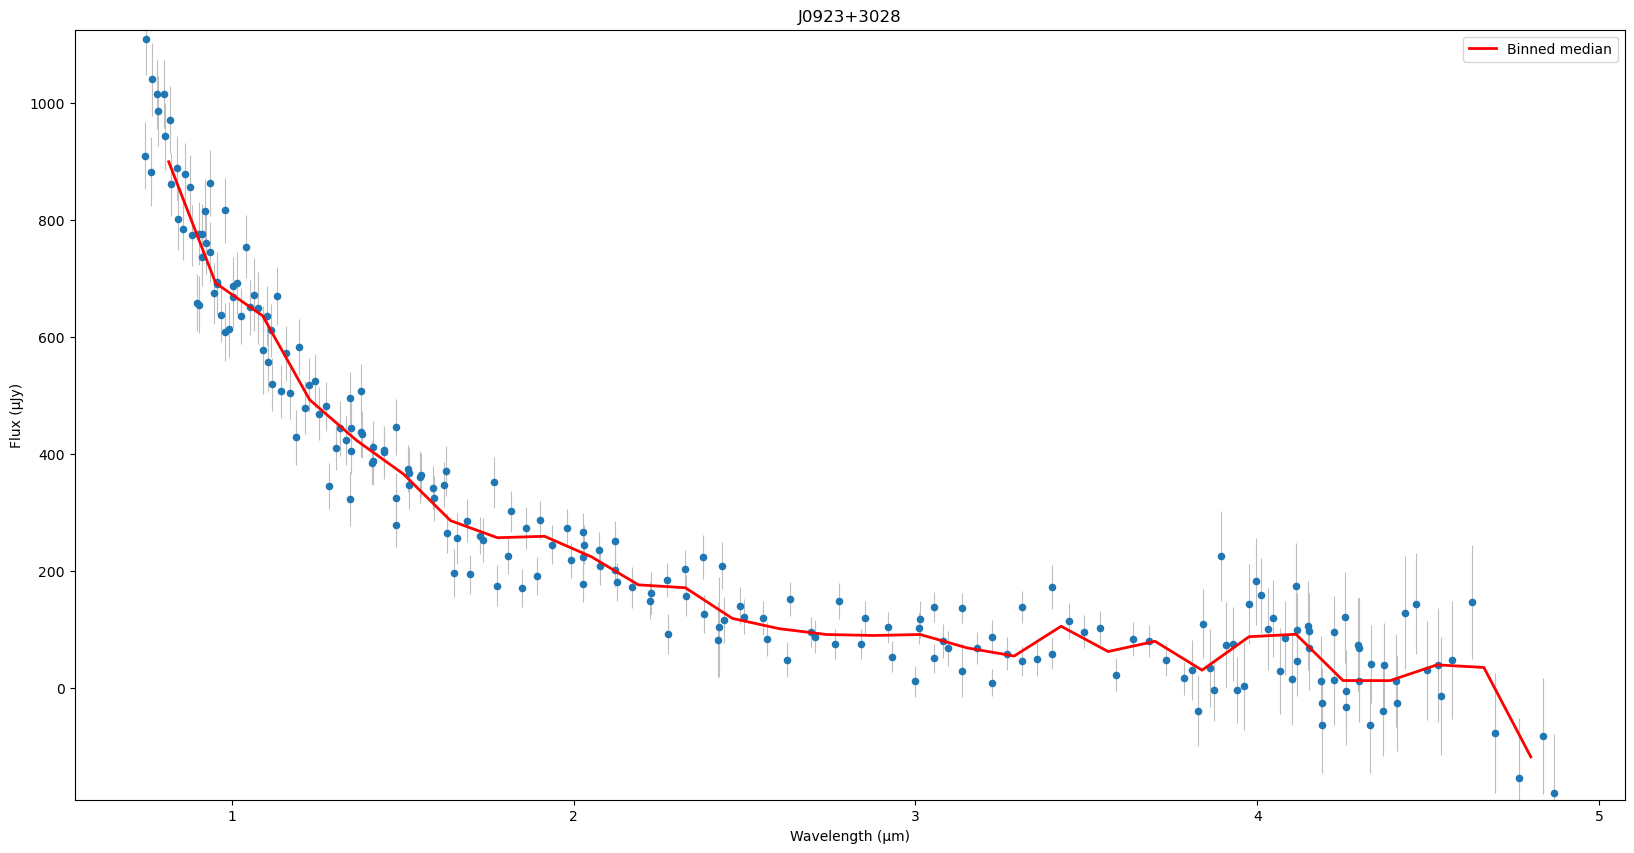

In [5]:
t, wl, f, err = load_lightcurve(
    "/Users/leighharwell2/Desktop/DW/IRchara/datasources/lightcurve/J0923+3028.tbl",
    cols={"t": "mjd", "wl": "lambda", "f": "flux", "err": "flux_err"},
)
t, wl, f, err = clean(t, wl, f, err)
plot_spectrum(t, wl, f, err, title="J0923+3028")
plt.show()

## Test Plot based on J0923 to check that all of the functions work correctly

In [6]:
from pathlib import Path

for path in sorted(Path("/Users/leighharwell2/Desktop/DW/IRchara/datasources/lightcurve").glob("*.tbl")):
    t, wl, f, err = load_lightcurve(path)
    t, wl, f, err = clean(t, wl, f, err)
    fig, ax = plot_spectrum(t, wl, f, err, title=path.stem)
    fig.savefig(path.with_suffix(".png"), dpi=200, bbox_inches="tight")
    plt.close(fig)

329 -> 295 after quality cuts -> 295 after clipping
564 -> 504 after quality cuts -> 502 after clipping
223 -> 200 after quality cuts -> 199 after clipping
242 -> 216 after quality cuts -> 216 after clipping
274 -> 246 after quality cuts -> 246 after clipping
371 -> 333 after quality cuts -> 333 after clipping
382 -> 342 after quality cuts -> 341 after clipping
473 -> 424 after quality cuts -> 422 after clipping
339 -> 305 after quality cuts -> 303 after clipping
335 -> 300 after quality cuts -> 300 after clipping
401 -> 359 after quality cuts -> 357 after clipping
223 -> 199 after quality cuts -> 199 after clipping
407 -> 365 after quality cuts -> 362 after clipping
338 -> 303 after quality cuts -> 301 after clipping


saving the figures to the same directory as the code

In [7]:
from pathlib import Path

folder = Path("/Users/leighharwell2/Desktop/DW/IRchara/datasources/lightcurve")
data = {}

for path in sorted(folder.glob("*.tbl")):
    t, wl, f, err = load_lightcurve(path, cols={"t": "mjd", "wl": "lambda", "f": "flux", "err": "flux_err"})
    data[path.stem] = clean(t, wl, f, err, verbose=False)

print(len(data), "tables loaded")   # should be 9

14 tables loaded


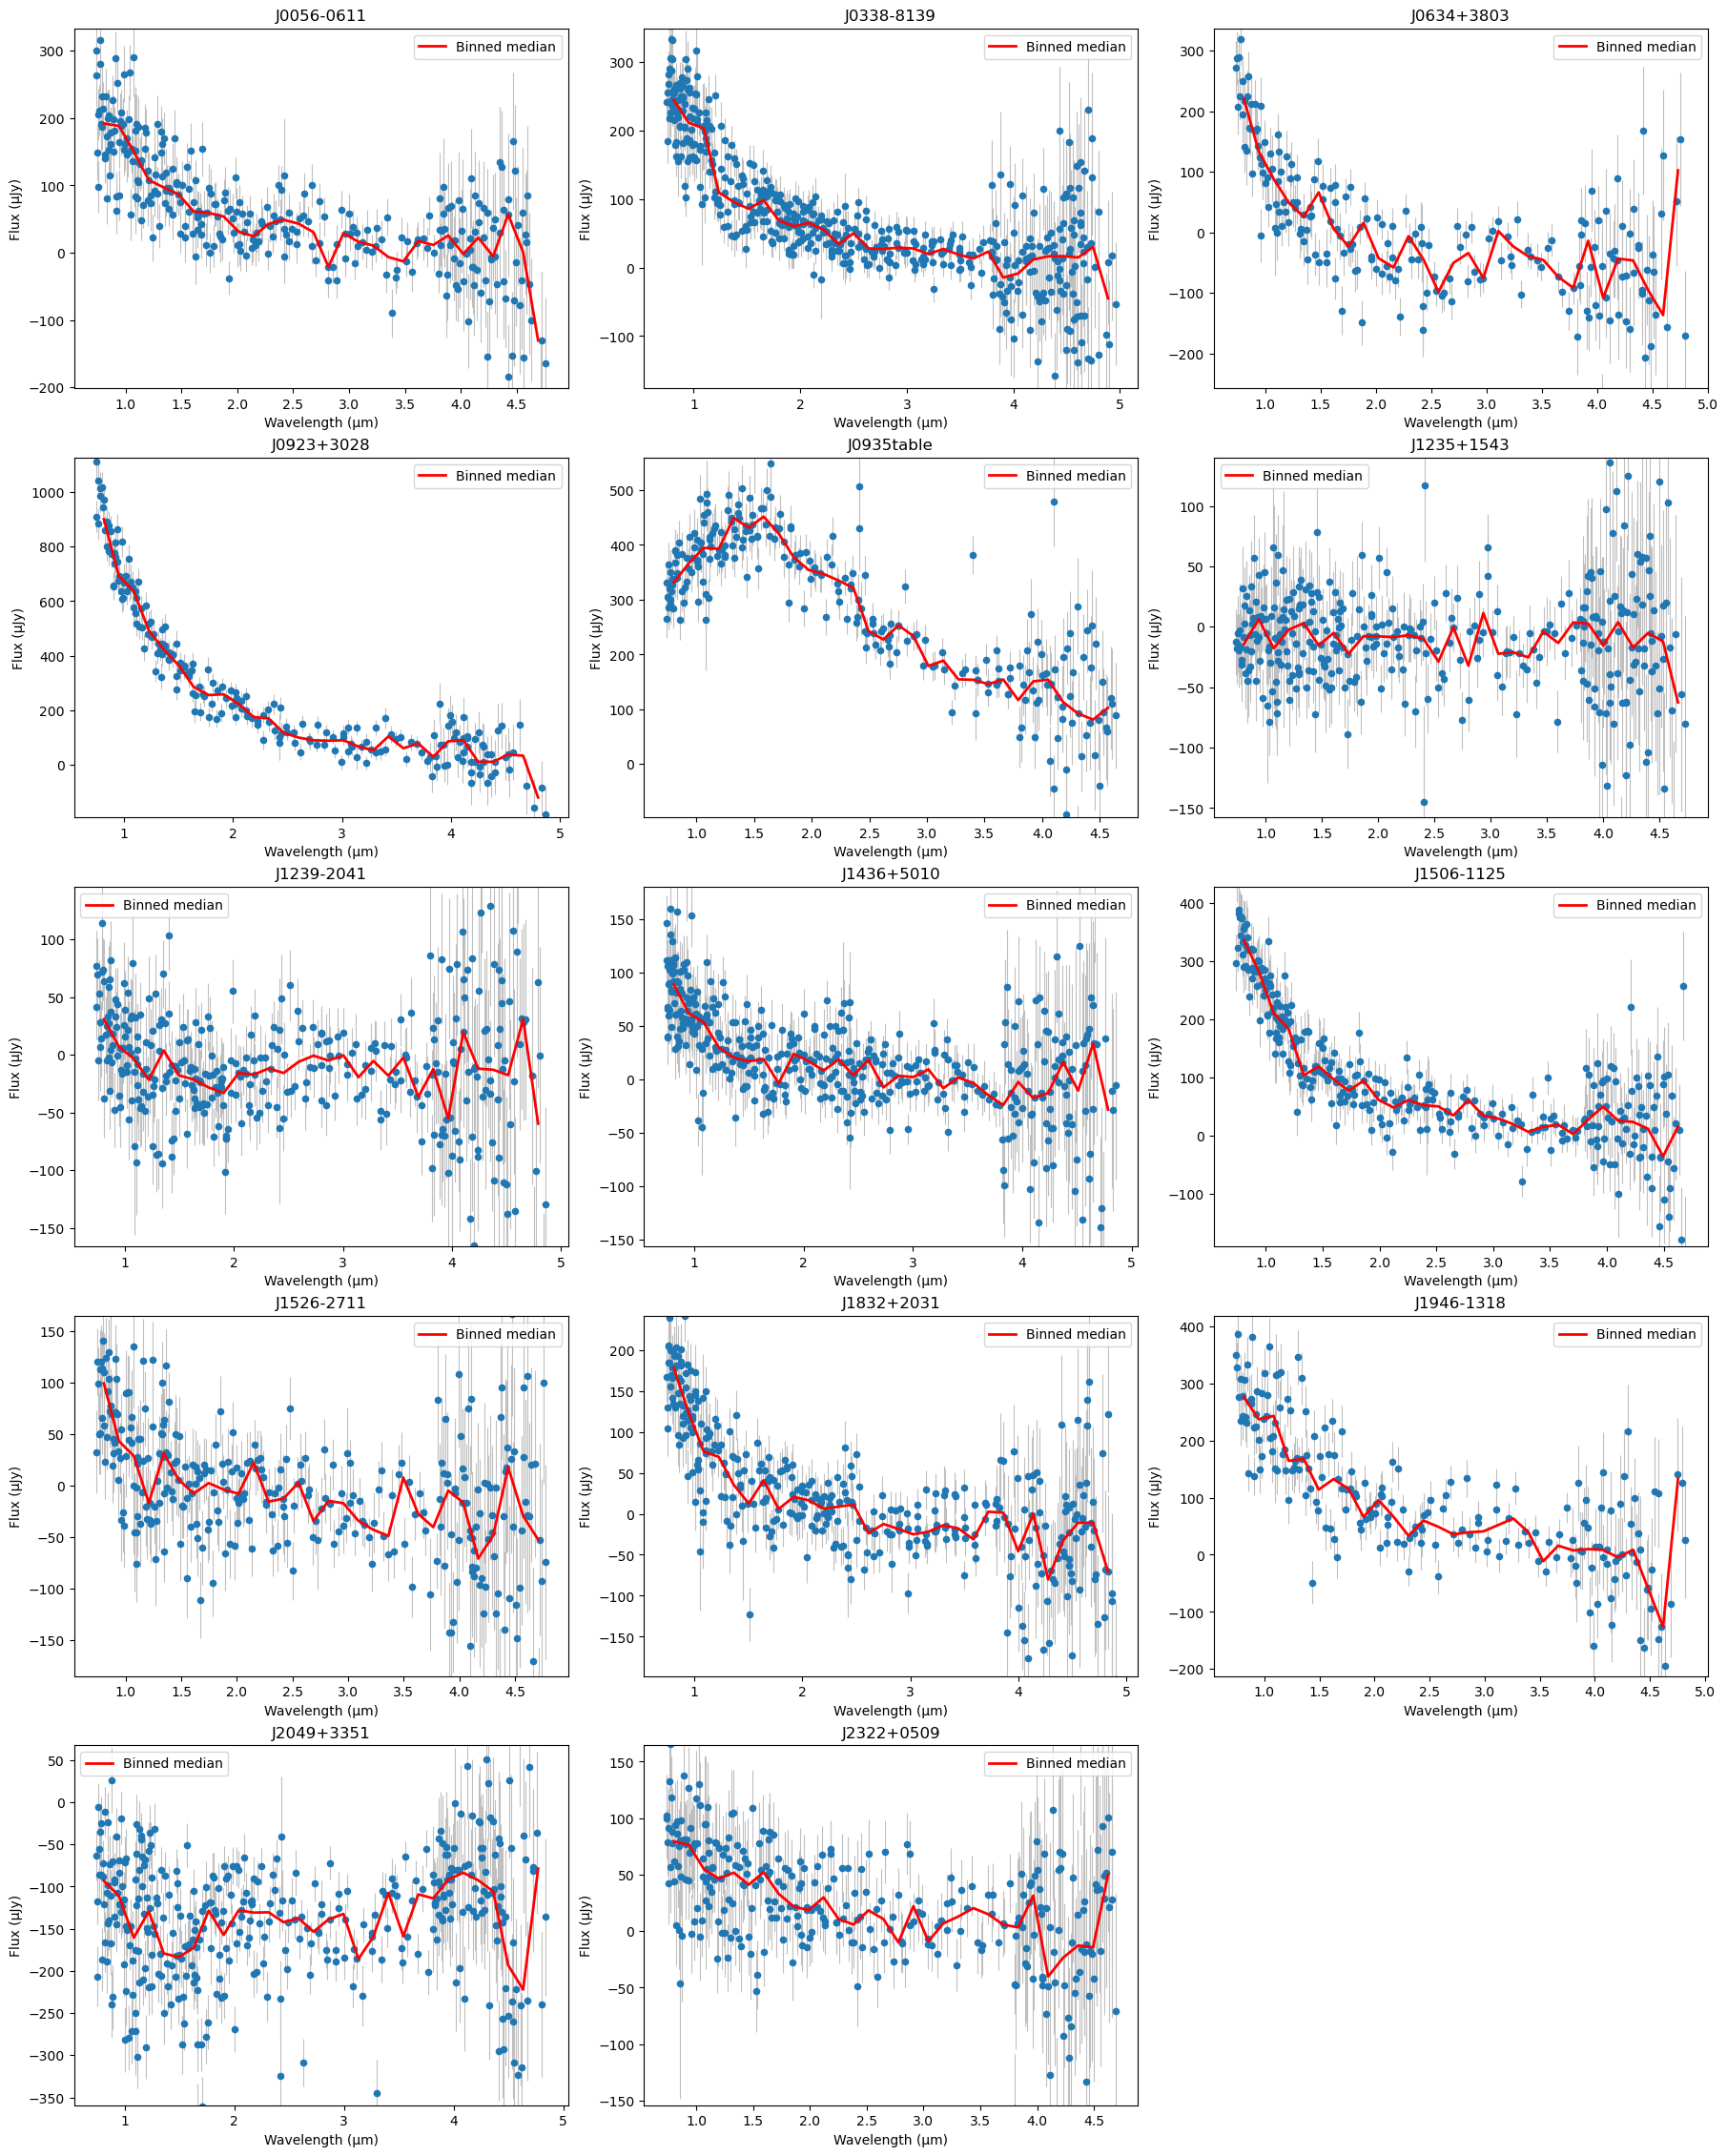

In [8]:
import math

n = len(data)
ncols = 3
nrows = math.ceil(n / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 4.5 * nrows),
                         constrained_layout=True)
axes = np.atleast_1d(axes).ravel()

for ax, (name, (t, wl, f, err)) in zip(axes, data.items()):
    plot_spectrum(t, wl, f, err, title=name, ax=ax)

# hide any unused panels
for ax in axes[n:]:
    ax.set_visible(False)

plt.show()

all 14 systems for the test run

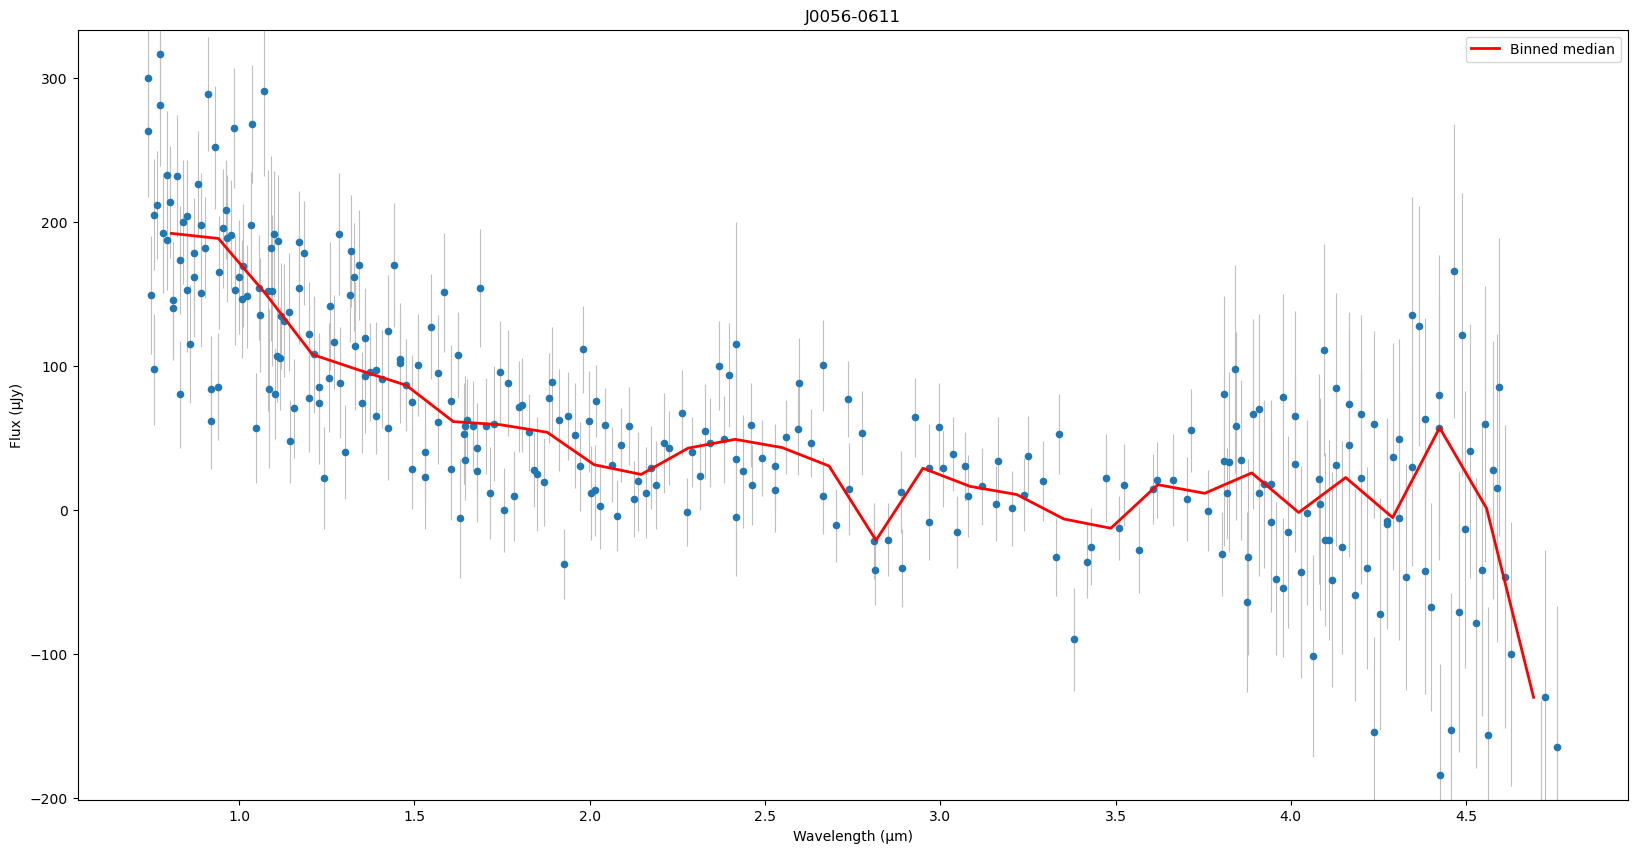

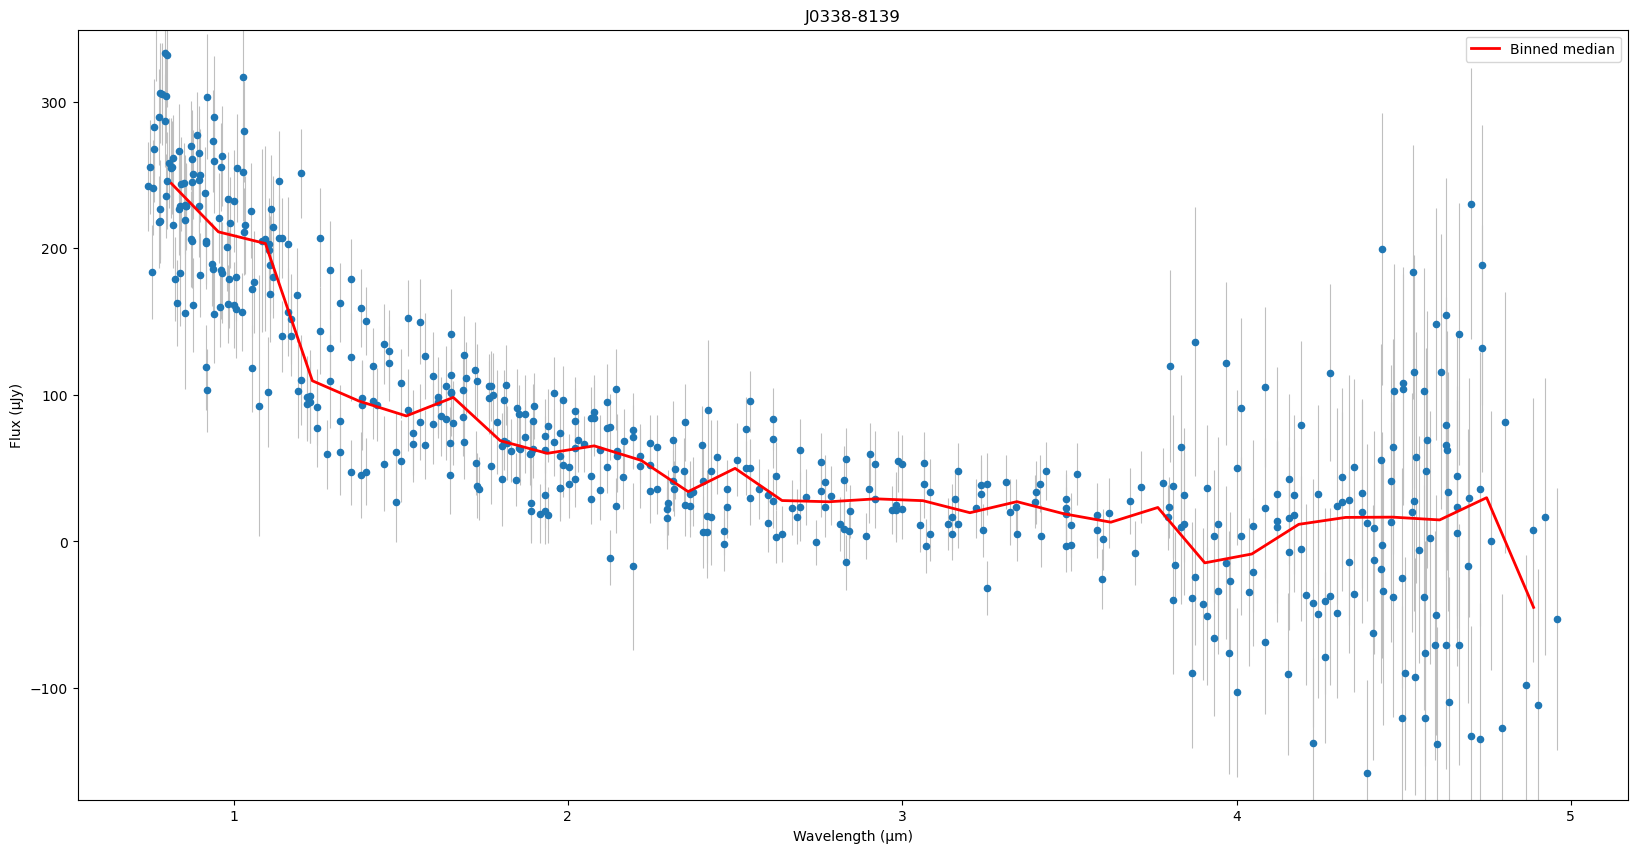

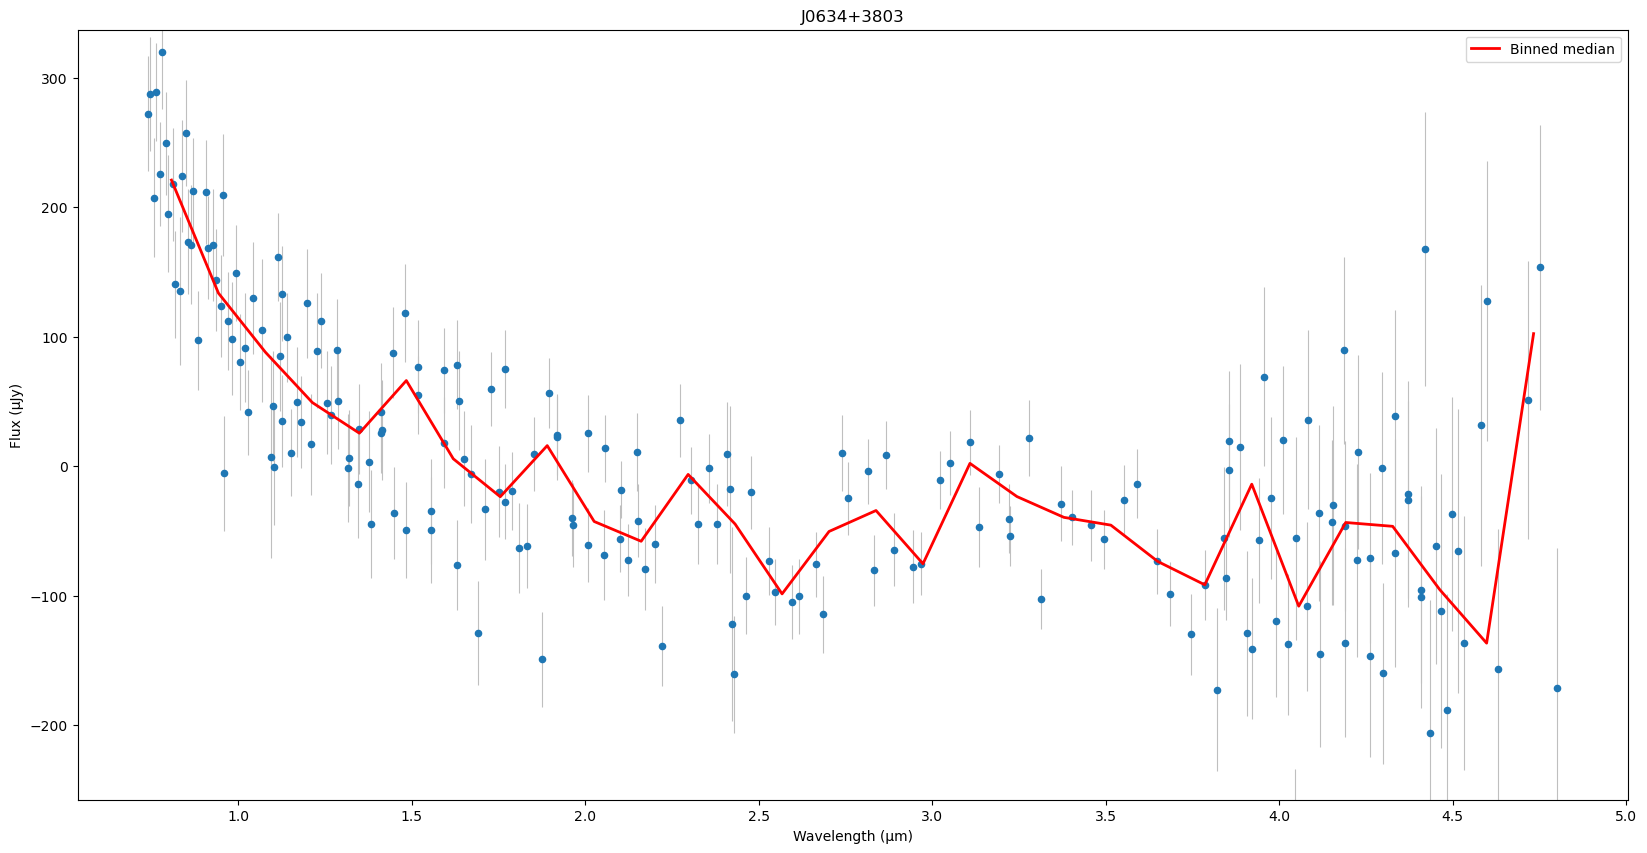

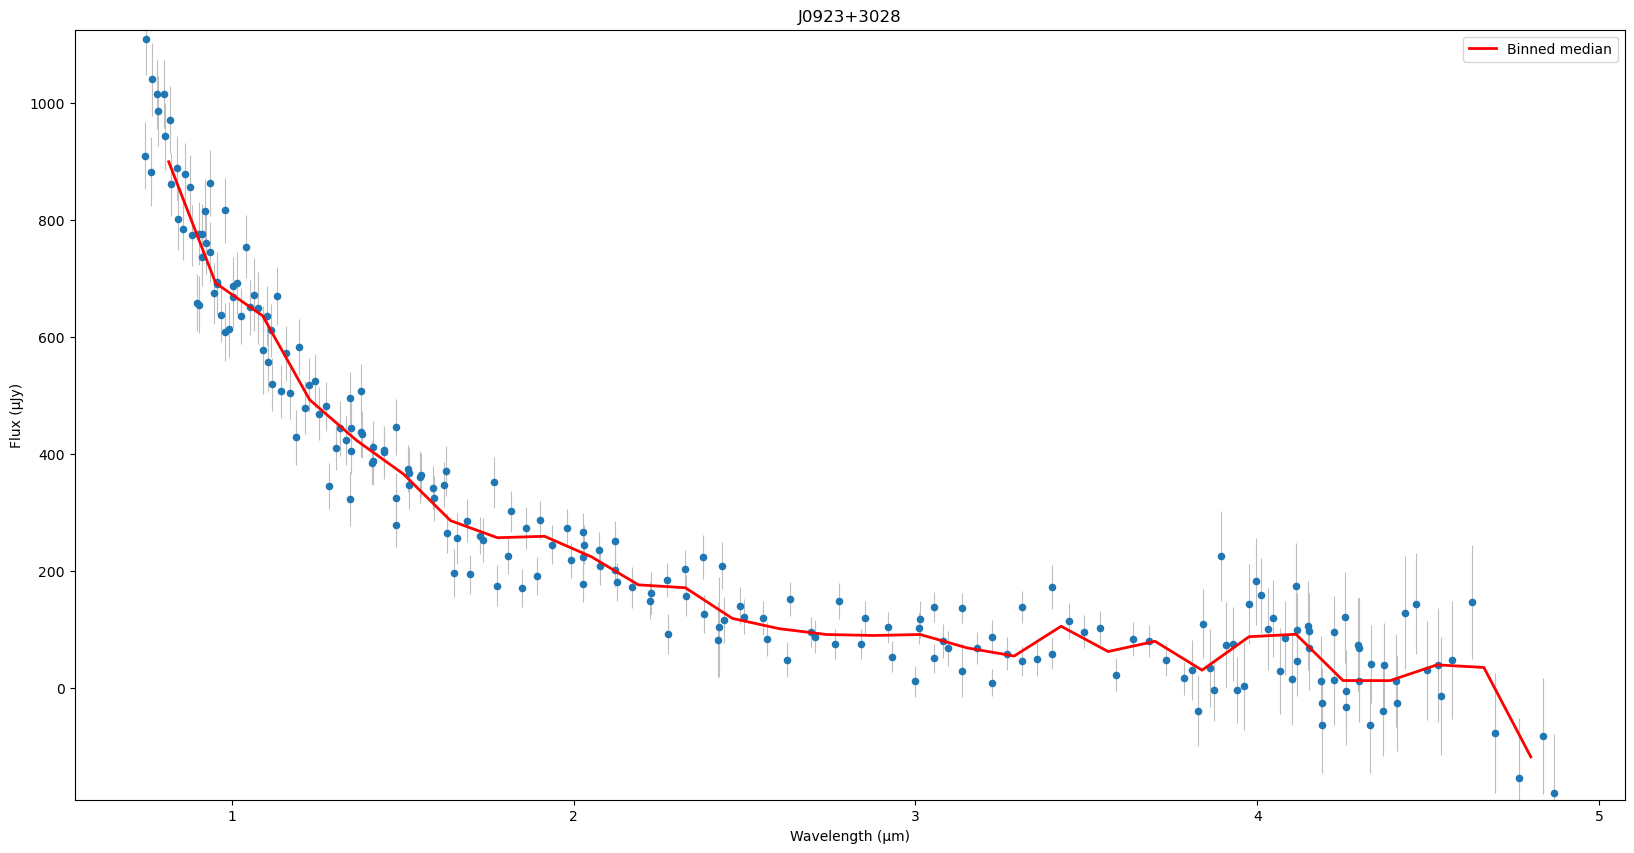

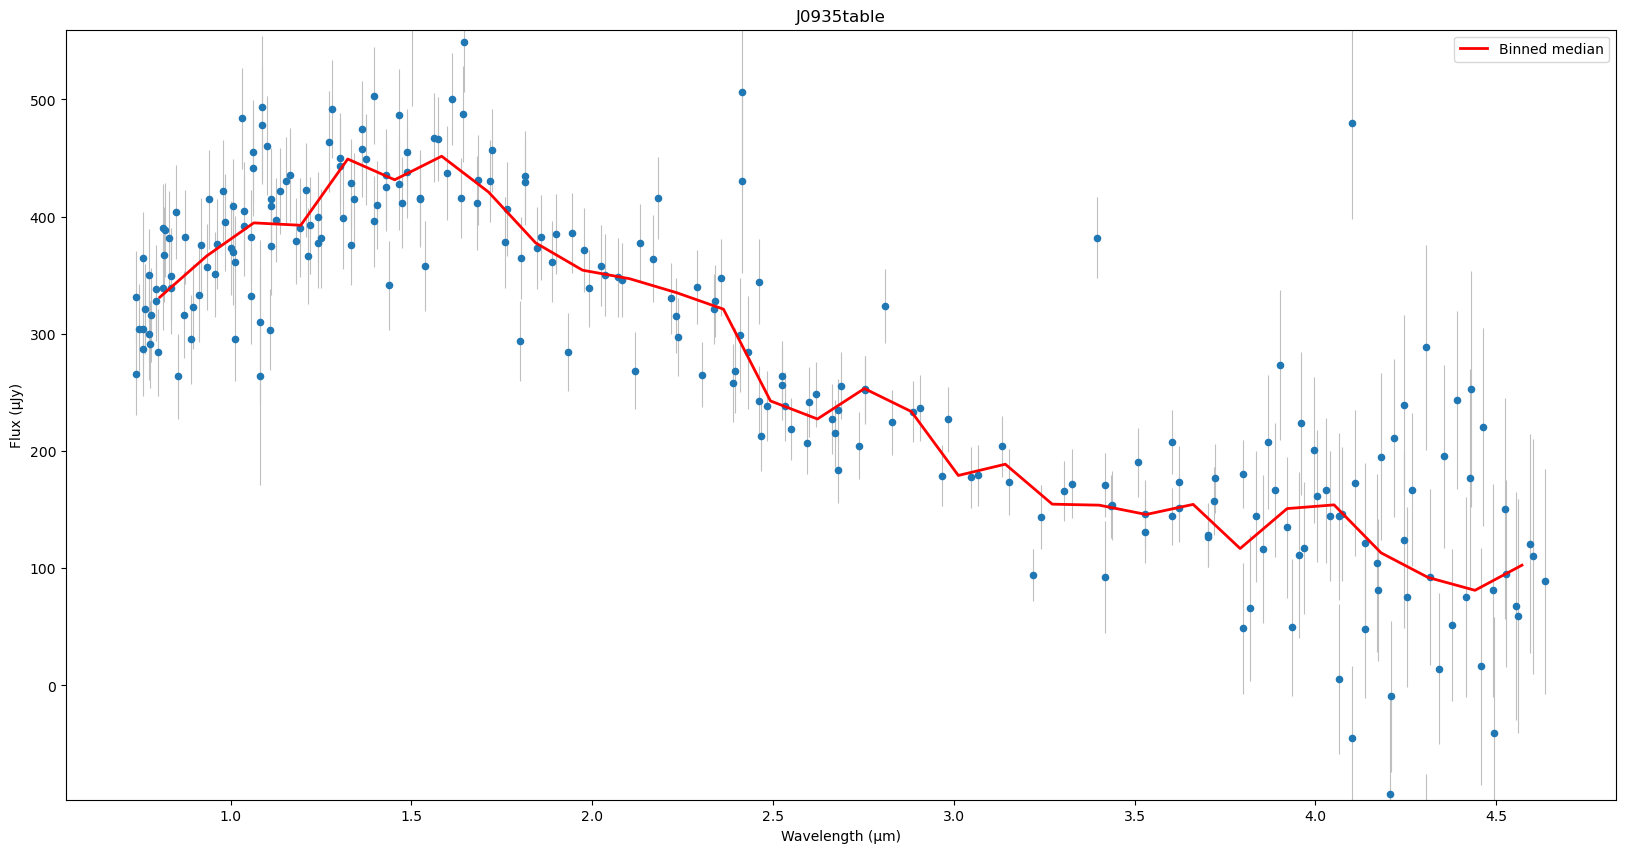

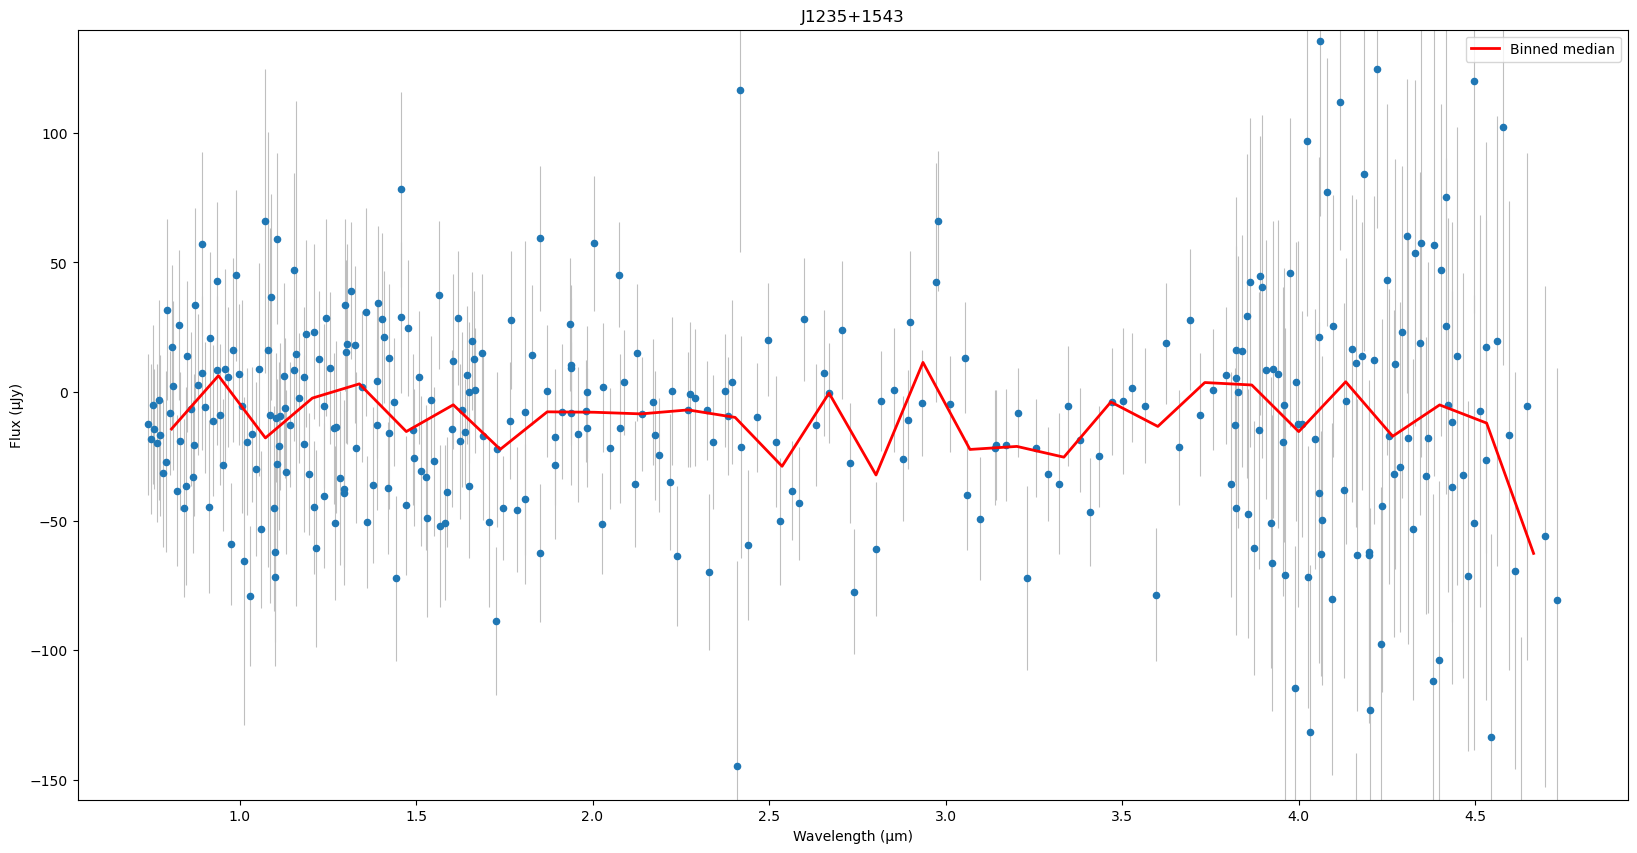

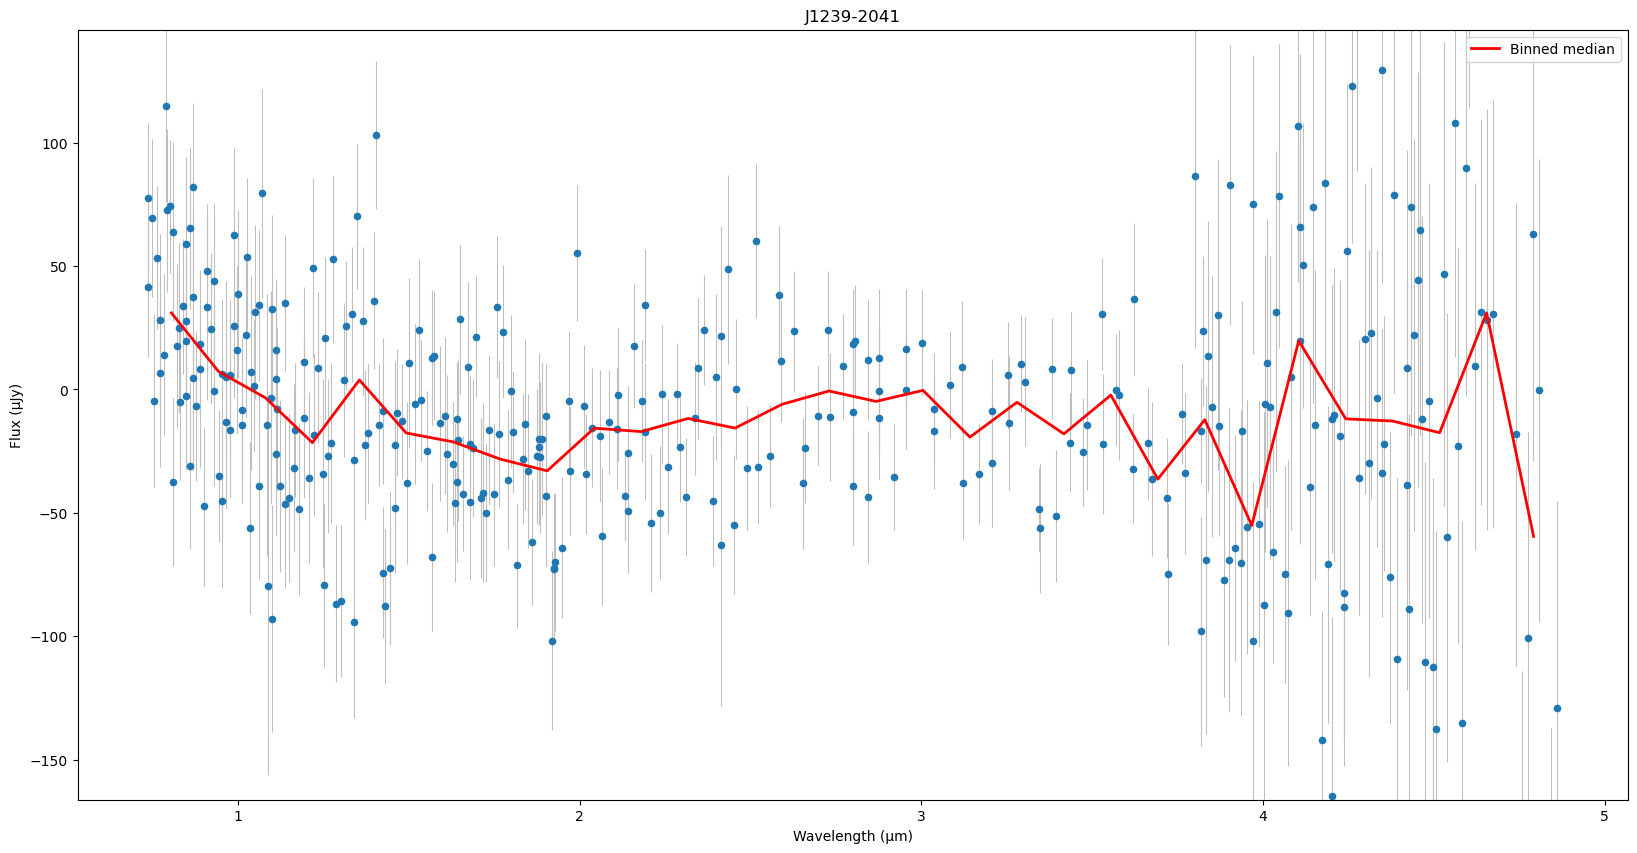

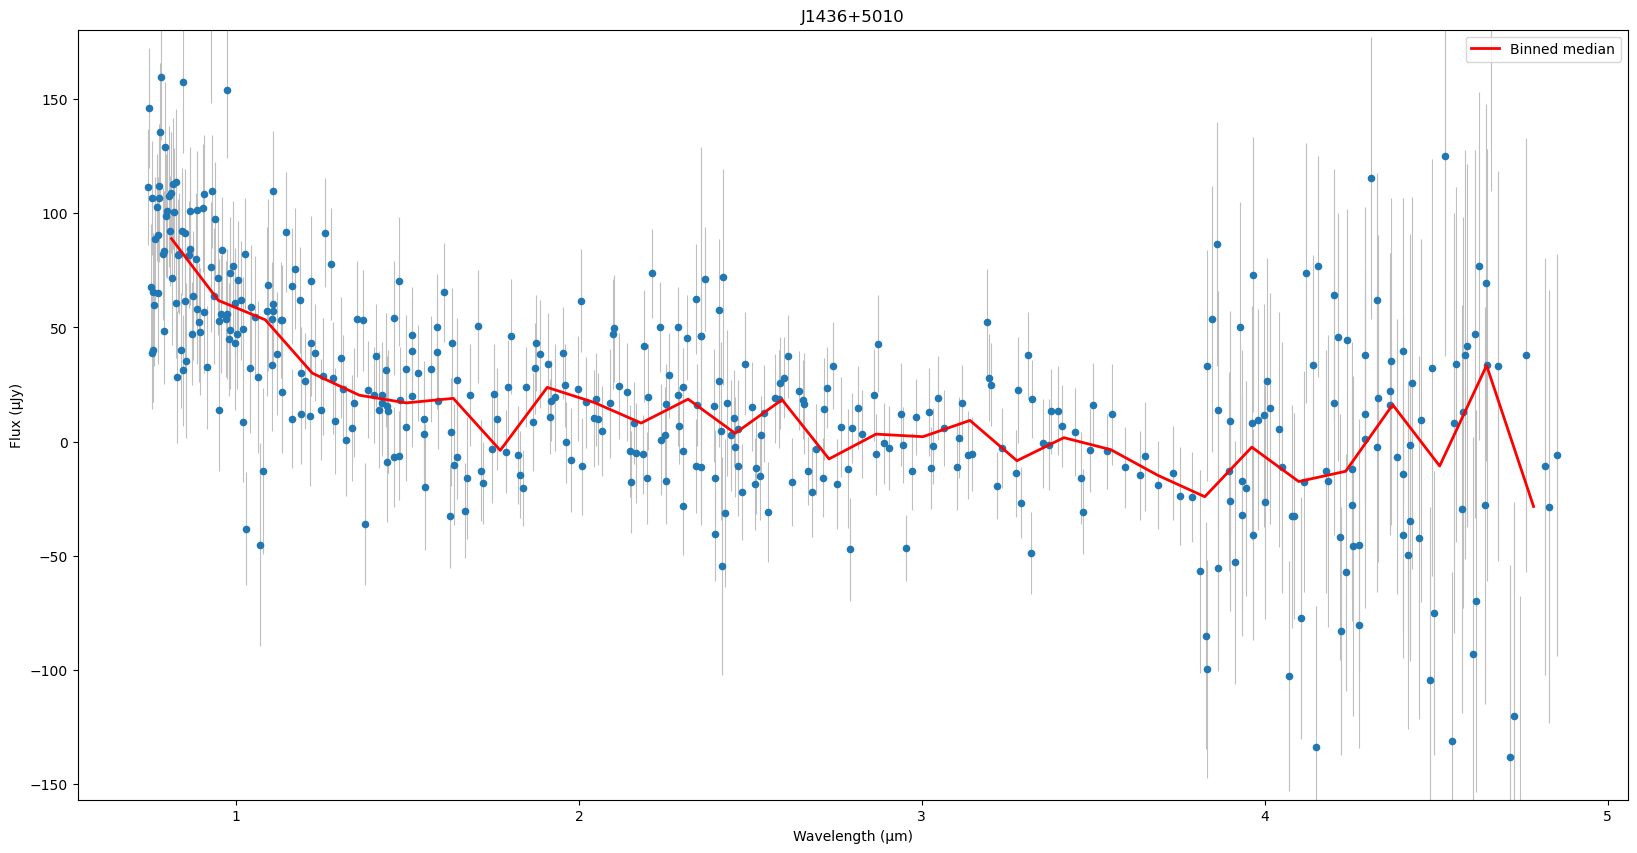

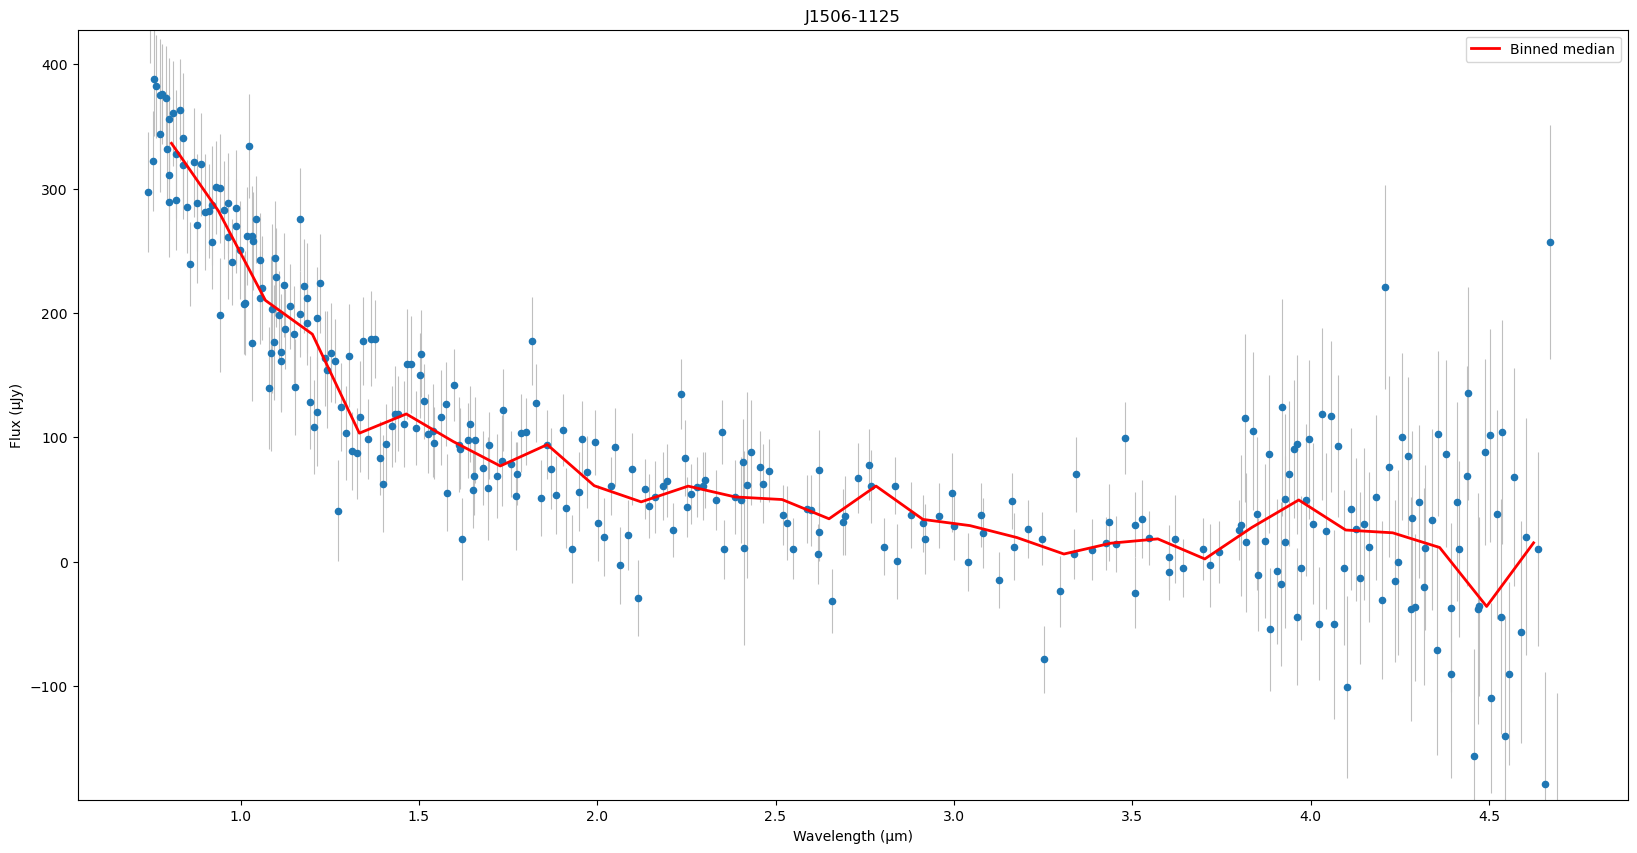

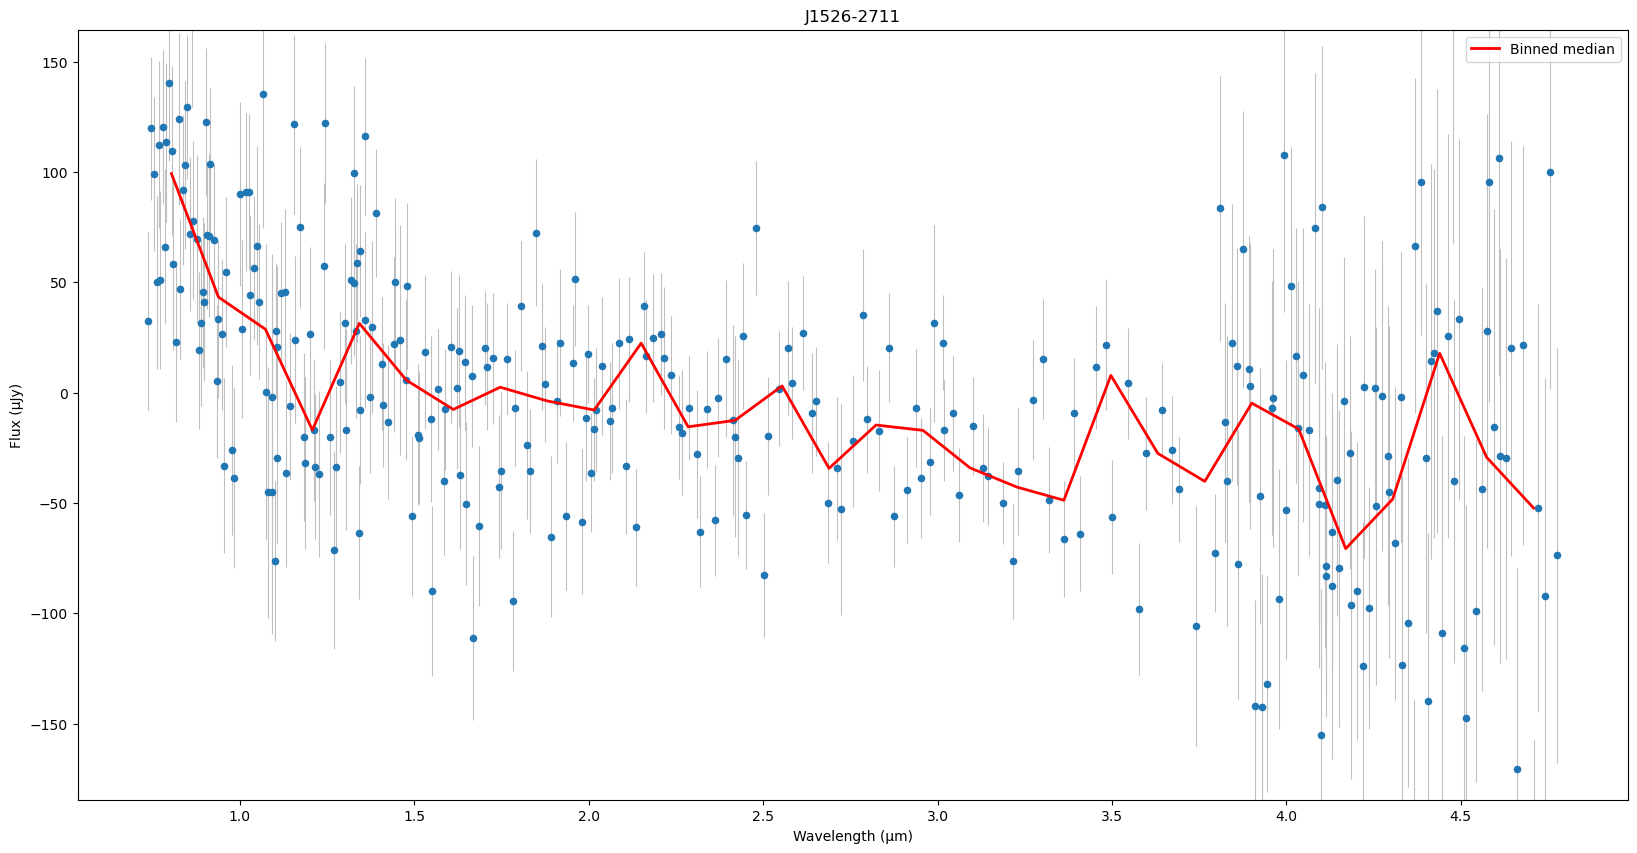

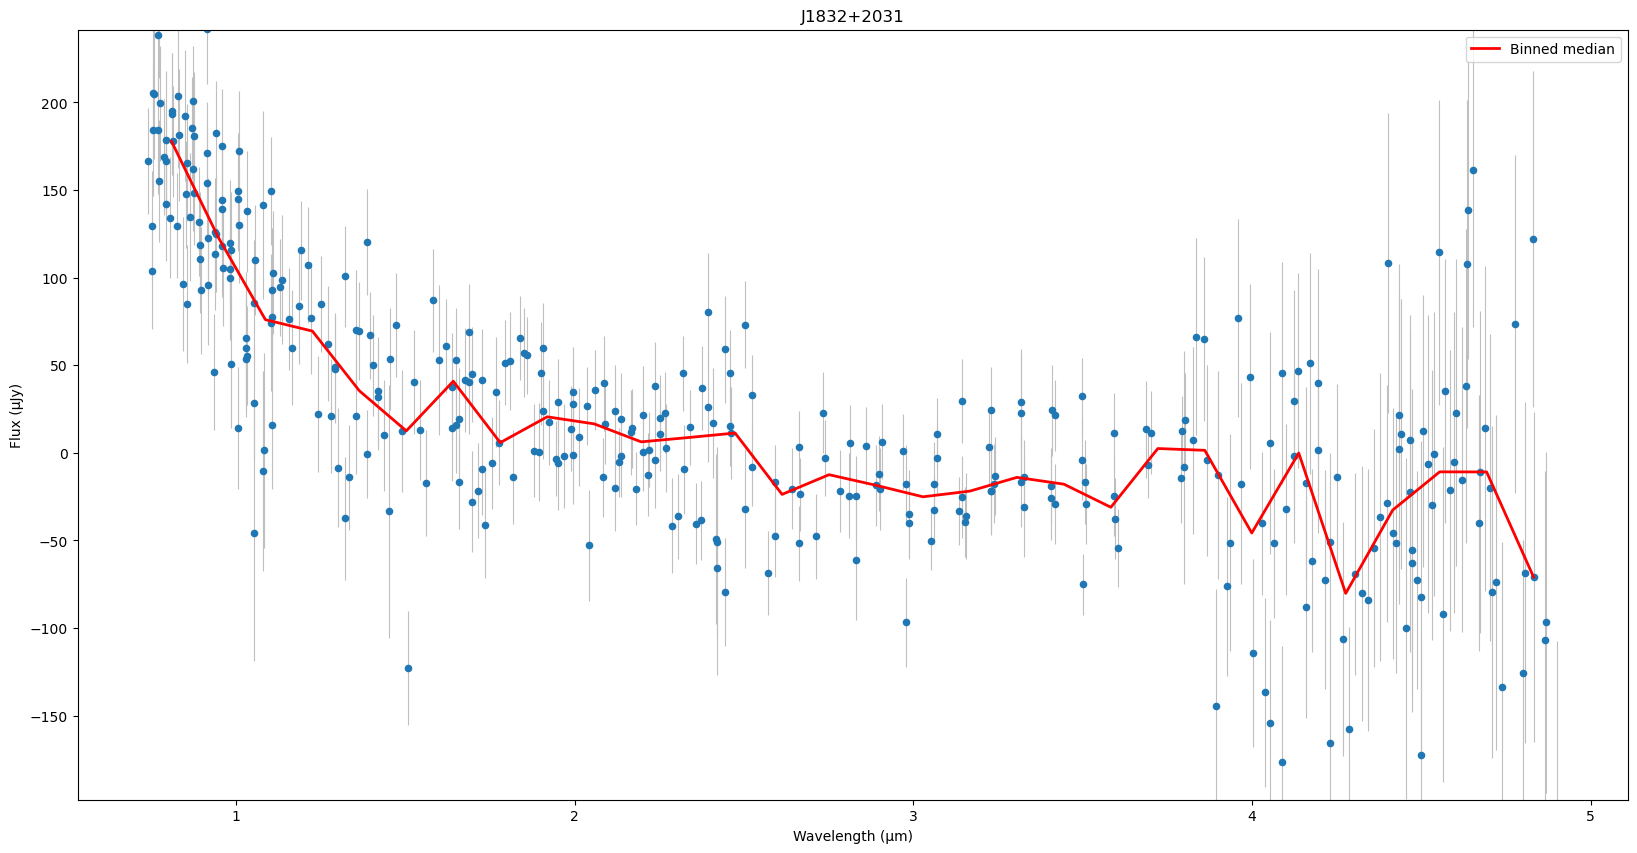

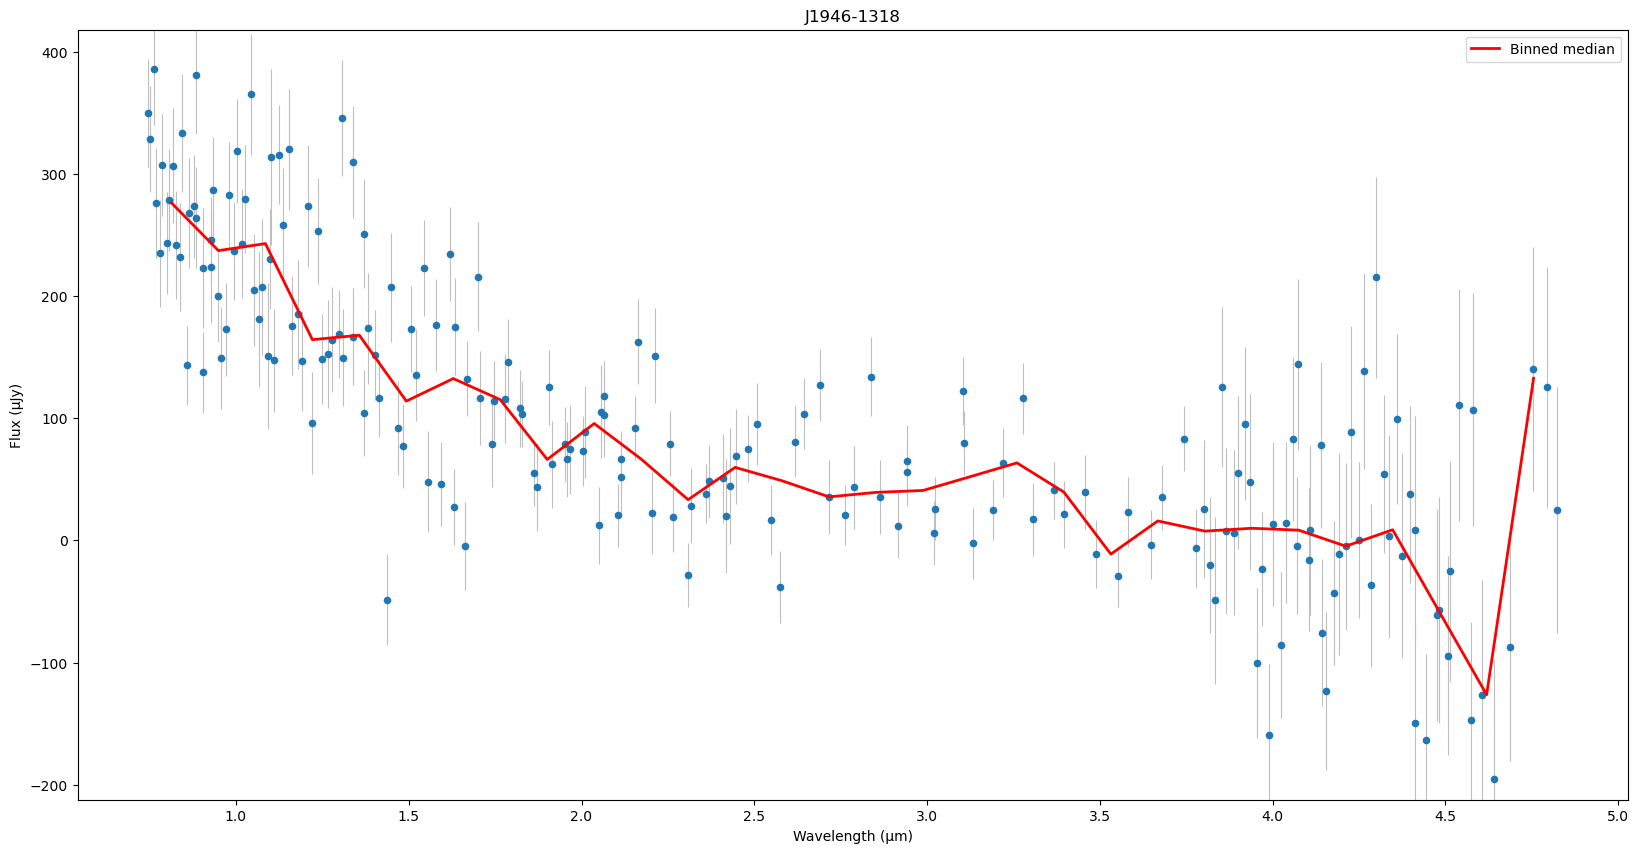

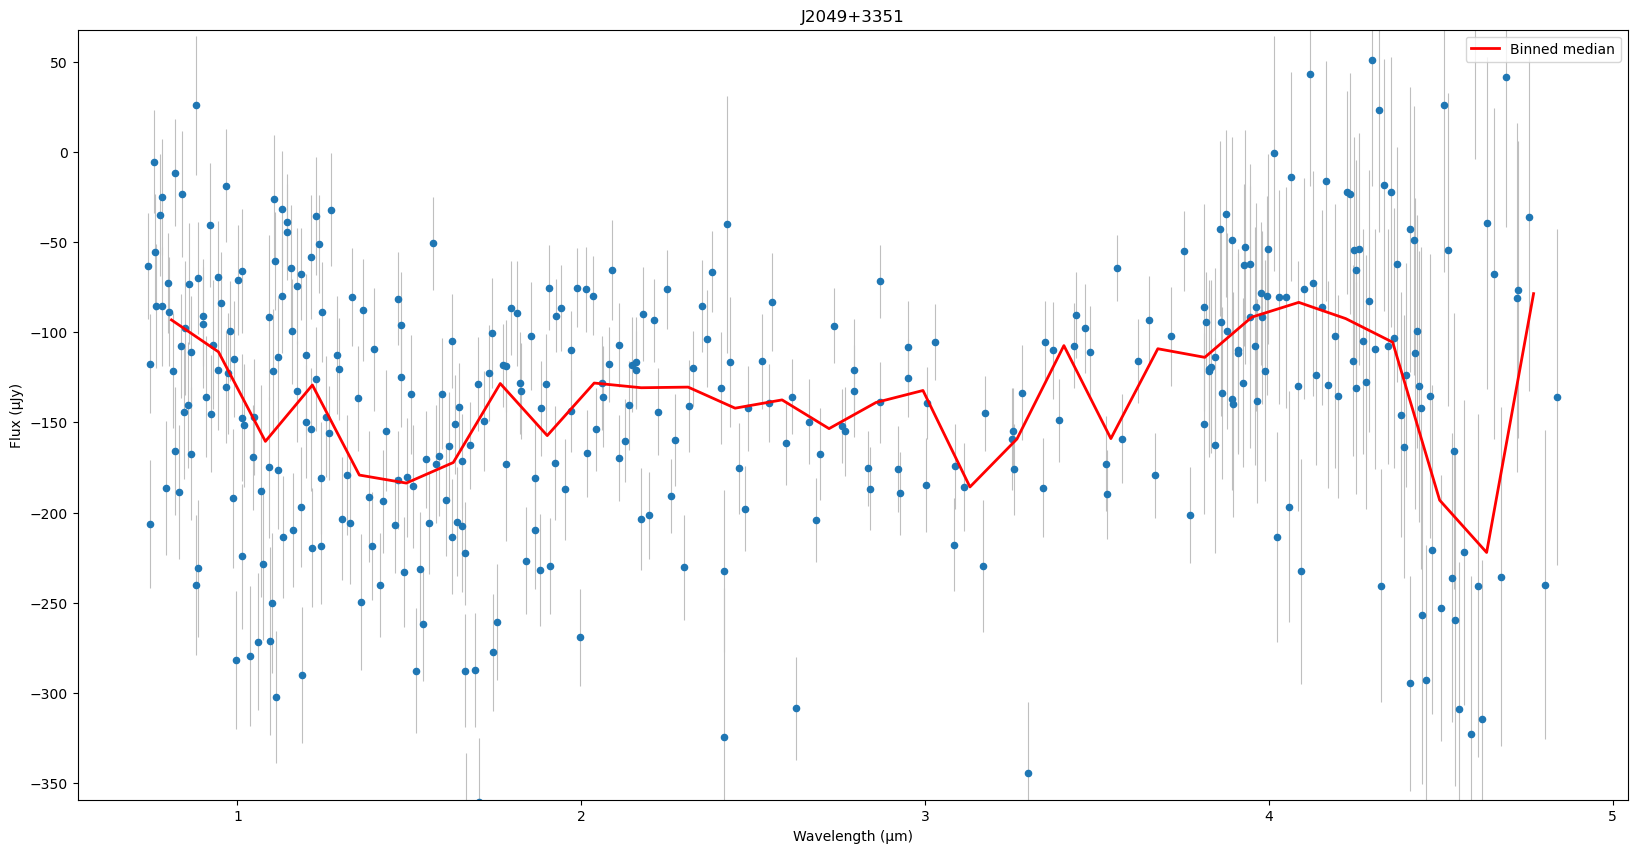

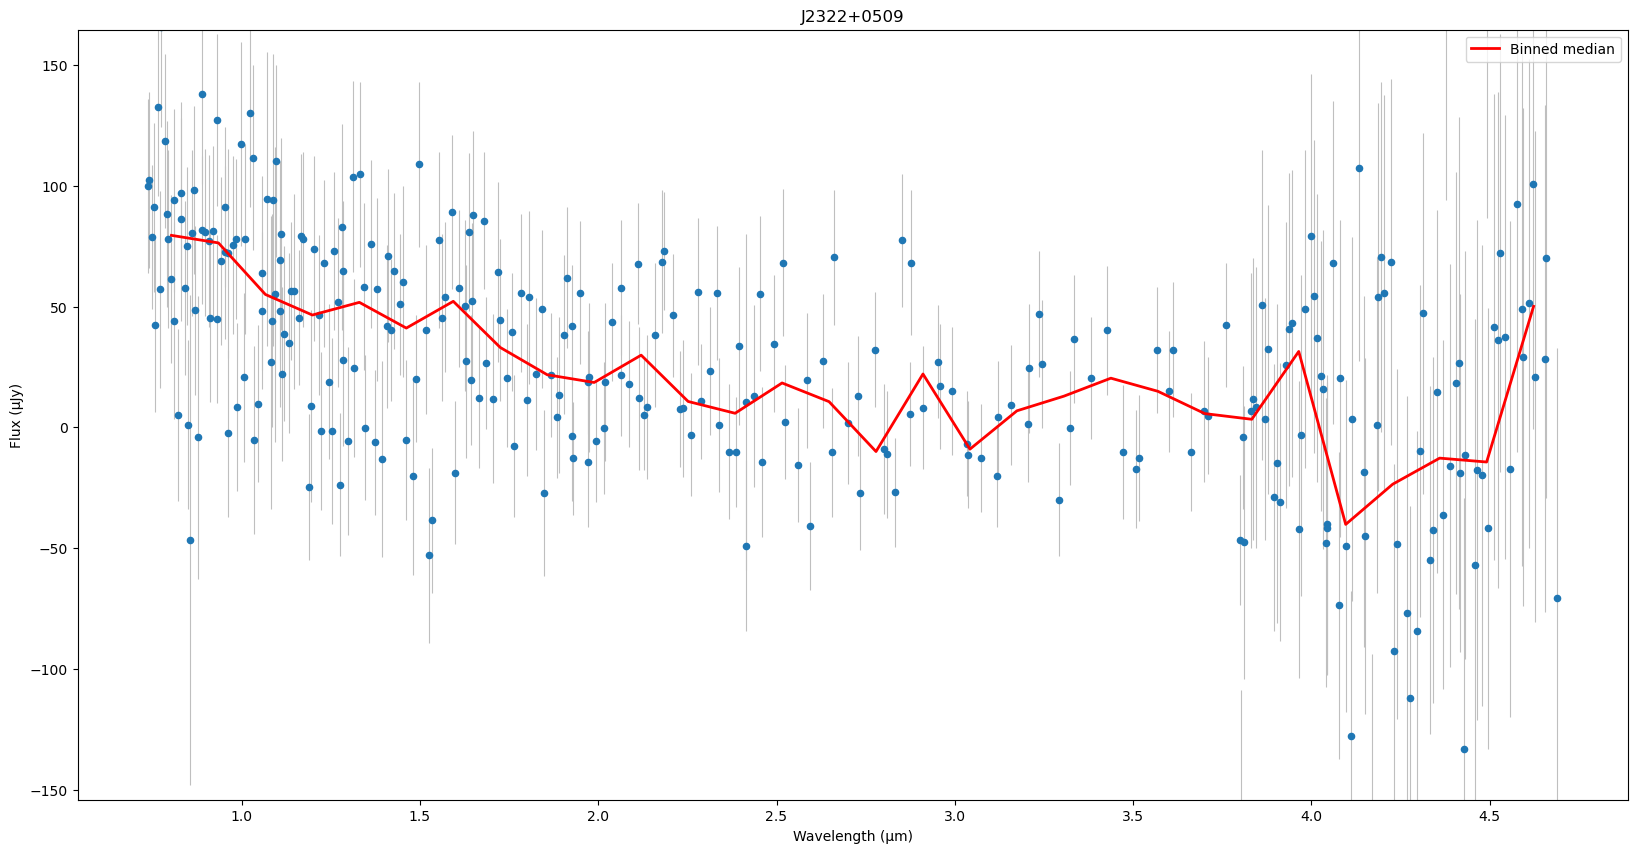

In [9]:
for name, (t, wl, f, err) in data.items():
    fig, ax = plot_spectrum(t, wl, f, err, title=name)
    plt.show()